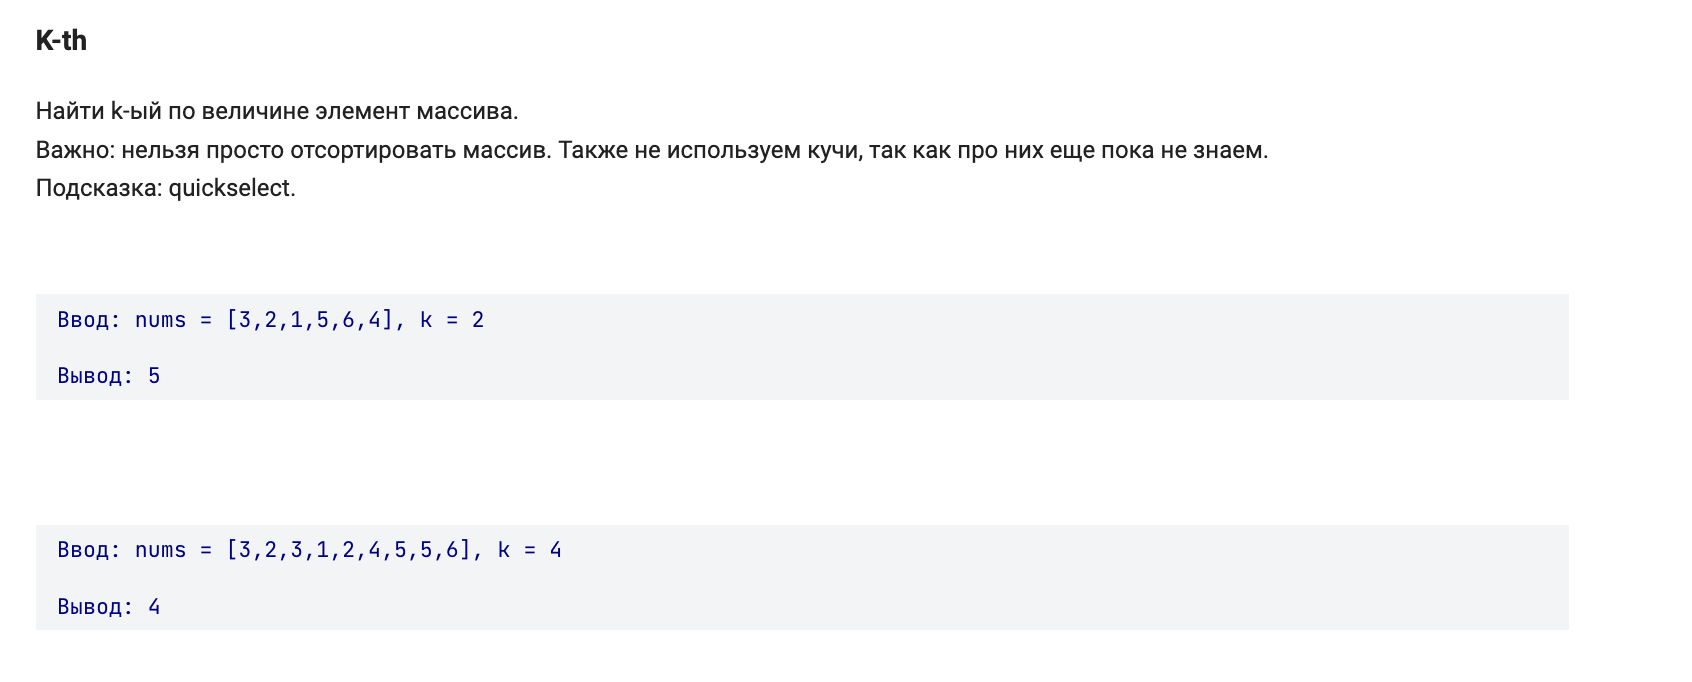


# Ход решения

Будем использовать **Quickselect**, алгоритм поиска k-го по величине элемента массива, основанный на той же идее разбиения, что и Quick Sort. Главное отличие заключается в том, что нам не нужно полностью сортировать массив: достаточно определить, в какой его части находится искомый элемент, и продолжить поиск только там.

Сначала определяем индекс искомого элемента. По условию `k` отсчитывается от наибольшего числа, то есть `k = 1` соответствует максимальному элементу. Поскольку индексы Python начинаются с нуля, а разбиение выполняется в порядке возрастания, нужная позиция вычисляется как `target = len(nums) - k`. Например, для массива `[3, 2, 1, 5, 6, 4]` при `k = 2` получаем `target = 4`, то есть ищем элемент, который находился бы на индексе 4 в отсортированном массиве. При этом одинаковые значения учитываются как отдельные элементы.

Далее выбираем случайный опорный элемент (`pivot`) из текущего диапазона массива. Случайный выбор помогает избежать систематически неудачных разбиений, которые могут возникать при использовании фиксированной позиции, например последнего элемента уже отсортированного массива. Благодаря этому Quickselect имеет ожидаемую временную сложность $O(n)$. Для воспроизводимости результатов и визуализации используем генератор `random.Random(7)`.

После выбора `pivot` выполняем **трёхстороннее разбиение**. В отличие от обычного Quick Sort, где элементы делятся на две части, здесь мы выделяем три группы: элементы меньше `pivot`, равные ему и больше него. Для этого используем три указателя: `lt` обозначает границу элементов меньше `pivot`, `gt` — границу элементов больше `pivot`, а `i` последовательно просматривает ещё не обработанные элементы.

Если `nums[i] < pivot`, меняем его с элементом на позиции `lt` и увеличиваем оба указателя `lt` и `i`. Если `nums[i] > pivot`, меняем его с элементом на позиции `gt` и уменьшаем `gt`, при этом `i` не увеличиваем, поскольку пришедший справа элемент ещё не проверен. Если `nums[i] == pivot`, просто увеличиваем `i`. В результате после завершения разбиения все элементы меньше `pivot` находятся слева, равные ему занимают непрерывный диапазон `[lt, gt]`, а большие справа.

Теперь остаётся определить, где находится нужный индекс `target`. Если `target < lt`, искомый элемент расположен в левой части массива, поэтому продолжаем поиск только в ней. Если `target > gt`, переходим к правой части. Если же `lt <= target <= gt`, ответ уже найден и равен `pivot`, поскольку все элементы этого диапазона имеют одинаковое значение.

Таким образом, **Quickselect на каждом шаге отбрасывает часть массива, которая точно не содержит искомую позицию**. В отличие от Quick Sort, мы не сортируем обе получившиеся части, а продолжаем работу только с одной из них. Именно поэтому при случайном выборе `pivot` ожидаемое время работы составляет $O(n)$, хотя в худшем случае возможна сложность $O(n^2)$.

# Граничные случаи
- Для пустого массива, `k=0` или `k>len(nums)` выбрасываем `ValueError`.
- `k=1` — максимальный элемент; `k=n` — минимальный.
- Дубликаты учитываются в ранге; трёхстороннее разбиение особенно полезно, когда одинаковых значений много.
- Отрицательные значения и ноль не требуют специальной обработки.
- Функция **меняет порядок элементов в исходном списке**, но не сортирует его целиком; если исходный порядок нужен, передавайте `nums.copy()`.


# Сложность алгоритма

- **Ожидаемое время — $O(n)$.** На каждом шаге Quickselect выполняет разбиение (`partition`), просматривая все элементы текущего подмассива за $O(n)$. Однако, в отличие от Quick Sort, после разбиения мы продолжаем поиск только в одной части, содержащей нужный индекс. Если `pivot` выбирается удачно и размер оставшейся части каждый раз уменьшается примерно вдвое, суммарная работа составляет:

  $$
  T(n)=n+\frac{n}{2}+\frac{n}{4}+\frac{n}{8}+\ldots < 2n
  $$

  Таким образом, получаем $O(n)$. Случайный выбор `pivot` не гарантирует деление пополам на каждом шаге, но позволяет получить линейную сложность в среднем по случайным выборам опорного элемента.

- **Худшее время — $O(n^2)$.** Если каждый раз выбирается крайне неудачный `pivot` (минимальный или максимальный элемент), после разбиения приходится продолжать поиск в подмассиве размером `n-1`. На следующем шаге остаётся `n-2` элементов и так далее. В результате количество операций пропорционально:

  $$
  T(n)=n+(n-1)+(n-2)+\ldots+1
  $$

  $$
  T(n)=\frac{n(n+1)}{2}=O(n^2)
  $$

  Случайный выбор `pivot` существенно снижает вероятность такой последовательности неудачных разбиений, но полностью её не исключает.

- **Дополнительная память — $O(1)$.** Алгоритм использует только несколько указателей (`left`, `right`, `lt`, `i`, `gt`) и переменных (`pivot`, `target`). Разбиение выполняется непосредственно внутри исходного массива, без создания дополнительных списков. Вместо рекурсии используется обычный цикл `while`, поэтому дополнительный стек вызовов также не требуется. Количество вспомогательных переменных не зависит от размера массива.

# Реализация алгоритма

In [1]:
import random


def kth_largest(nums, k, *, rng=None, trace=None):
    if not 1 <= k <= len(nums):
        raise ValueError('k должно быть от 1 до len(nums)')

    rng = rng or random
    target = len(nums) - k
    left, right = 0, len(nums) - 1

    while left <= right:
        pivot = nums[rng.randrange(left, right + 1)]
        lt = i = left
        gt = right

        while i <= gt:
            if nums[i] < pivot:
                nums[lt], nums[i] = nums[i], nums[lt]
                lt += 1
                i += 1
            elif nums[i] > pivot:
                nums[i], nums[gt] = nums[gt], nums[i]
                gt -= 1
            else:
                i += 1

        if trace is not None:
            trace.append((nums.copy(), left, right, lt, gt, pivot, target))

        if target < lt:
            right = lt - 1
        elif target > gt:
            left = gt + 1
        else:
            return nums[target]

# Проверка на нетривиальном примере

Возьмём второй пример из условия: `[3, 2, 3, 1, 2, 4, 5, 5, 6]`, `k = 4`.

Всего `n = 9` элементов, значит, индекс нужного элемента в массиве по возрастанию равен:

$$
\text{target} = n-k = 9-4 = 5.
$$

Вместо полной сортировки достаточно последовательно разбивать текущий отрезок. Трассировка ниже показывает на каждом шаге выбранный `pivot`, три полученные группы и то, в какую сторону продолжается поиск.

In [2]:
nums = [3, 2, 3, 1, 2, 4, 5, 5, 6]
trace = []
answer = kth_largest(nums.copy(), 4, rng=random.Random(1), trace=trace)

for step, (values, left, right, lt, gt, pivot, target) in enumerate(trace, 1):
    smaller = values[left:lt]
    equal = values[lt:gt + 1]
    larger = values[gt + 1:right + 1]
    direction = 'налево' if target < lt else 'направо' if target > gt else 'найдено'
    print(f'Шаг {step}: pivot={pivot}, диапазон [{left}, {right}]')
    print(f'  < pivot: {smaller} | == pivot: {equal} | > pivot: {larger}')
    print(f'  Массив: {values} | индекс {target}, действие: {direction}')

print('\nОтвет:', answer)
assert answer == 4
assert kth_largest([3, 2, 1, 5, 6, 4], 2, rng=random.Random(7)) == 5

Шаг 1: pivot=3, диапазон [0, 8]
  < pivot: [2, 1, 2] | == pivot: [3, 3] | > pivot: [5, 5, 6, 4]
  Массив: [2, 1, 2, 3, 3, 5, 5, 6, 4] | индекс 5, действие: направо
Шаг 2: pivot=5, диапазон [5, 8]
  < pivot: [4] | == pivot: [5, 5] | > pivot: [6]
  Массив: [2, 1, 2, 3, 3, 4, 5, 5, 6] | индекс 5, действие: налево
Шаг 3: pivot=4, диапазон [5, 5]
  < pivot: [] | == pivot: [4] | > pivot: []
  Массив: [2, 1, 2, 3, 3, 4, 5, 5, 6] | индекс 5, действие: найдено

Ответ: 4


# Визуализация работы алгоритма

На нашем примере `target = 5`, потому что `n - k = 9 - 4`.

| Шаг | `pivot` | Расположение внутри активного отрезка | Что делаем |
| --- | --- | --- | --- |
| 1 | 3 | `[2, 1, 2]` · `[3, 3]` · `[5, 5, 6, 4]` | Индекс `5` справа от равных → ищем справа |
| 2 | 5 | `[4]` · `[5, 5]` · `[6]` | Индекс `5` левее равных → ищем слева |
| 3 | 4 | `[]` · `[4]` · `[]` | Индекс `5` попадает в равные → ответ `4` |

После трёх разбиений массив имеет вид `[2, 1, 2, 3, 3, 4, 5, 5, 6]`: **он не полностью отсортирован**, и это нормально. Мы нашли нужный элемент, не выполняя ненужную работу.

На рисунках ниже показано состояние **после очередного трёхстороннего разбиения**. Вертикальные пунктирные линии ограничивают группу элементов, равных `pivot`. Звёздочка возле числа отмечает искомый индекс `target` (считаем от нуля).

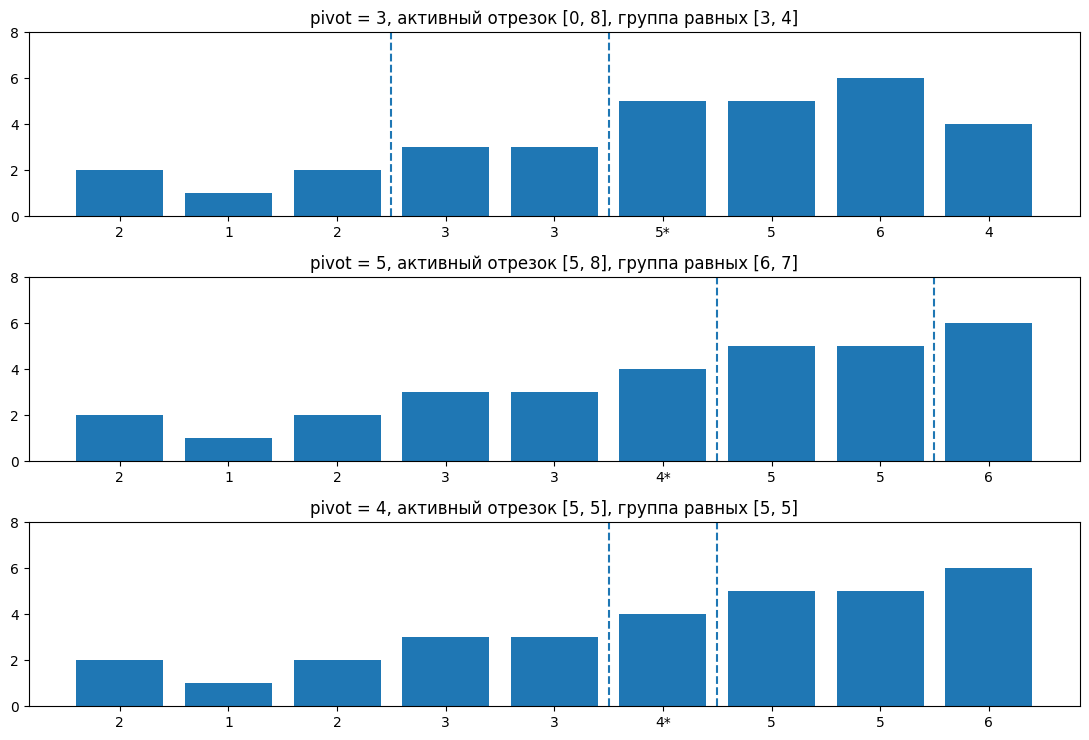

In [3]:
import matplotlib.pyplot as plt


fig, axes = plt.subplots(len(trace), 1, figsize=(11, max(3, 2.5 * len(trace))))
if len(trace) == 1:
    axes = [axes]

for ax, (values, left, right, lt, gt, pivot, target) in zip(axes, trace):
    ax.bar(range(len(values)), values)
    ax.axvline(lt - 0.5, linestyle='--')
    ax.axvline(gt + 0.5, linestyle='--')
    ax.set_xticks(range(len(values)), [f'{v}*' if i == target else str(v) for i, v in enumerate(values)])
    ax.set_ylim(0, max(values) + 2)
    ax.set_title(f'pivot = {pivot}, активный отрезок [{left}, {right}], группа равных [{lt}, {gt}]')

plt.tight_layout()
plt.show()

# Тесты

Проверим:
- два примера из условия;
- `k=1`, `k=n` и массив из одного элемента;
- одинаковые значения и дубликаты с повторными рангами;
- отрицательные числа и ноль;
- возрастающий, убывающий, большой случайный массив;
- неверные значения `k` и пустой массив;
- сохранение всех исходных значений (разрешены перестановки, но не потеря элементов).

Только в **тестах** используем `sorted(..., reverse=True)[k - 1]` как эталон. **Алгоритм Quickselect ничего не сортирует и не использует кучу**, что полностью соответствует условию.

In [4]:
from collections import Counter
import unittest


class TestQuickselect(unittest.TestCase):
    def check(self, values, k):
        original = values.copy()
        expected = sorted(values, reverse=True)[k - 1]
        self.assertEqual(kth_largest(values, k, rng=random.Random(13)), expected)
        self.assertEqual(Counter(values), Counter(original))

    def test_examples(self):
        self.check([3, 2, 1, 5, 6, 4], 2)
        self.check([3, 2, 3, 1, 2, 4, 5, 5, 6], 4)

    def test_singleton(self):
        self.check([42], 1)

    def test_first_and_last_rank(self):
        self.check([4, 0, 7, -2, 5], 1)
        self.check([4, 0, 7, -2, 5], 5)

    def test_duplicates(self):
        for k in range(1, 7):
            self.check([5, 1, 5, 2, 5, 3], k)
        self.check([7] * 100, 50)

    def test_negative_and_zero(self):
        for k in range(1, 7):
            self.check([-5, 0, -1, -3, 0, -5], k)

    def test_sorted_and_reversed(self):
        for values in (list(range(100)), list(range(99, -1, -1))):
            for k in (1, 2, 50, 100):
                self.check(values.copy(), k)

    def test_random_arrays(self):
        rng = random.Random(21)
        for size in (2, 5, 20, 100, 1000):
            values = [rng.randint(-50, 50) for _ in range(size)]
            for k in (1, max(1, size // 2), size):
                self.check(values.copy(), k)

    def test_invalid_k(self):
        for values, k in (([], 1), ([1, 2, 3], 0), ([1, 2, 3], -1), ([1, 2, 3], 4)):
            with self.subTest(values=values, k=k):
                with self.assertRaises(ValueError):
                    kth_largest(values, k)


suite = unittest.defaultTestLoader.loadTestsFromTestCase(TestQuickselect)
result = unittest.TextTestRunner(verbosity=2).run(suite)
assert result.wasSuccessful()

test_duplicates (__main__.TestQuickselect.test_duplicates) ... ok
test_examples (__main__.TestQuickselect.test_examples) ... ok
test_first_and_last_rank (__main__.TestQuickselect.test_first_and_last_rank) ... ok
test_invalid_k (__main__.TestQuickselect.test_invalid_k) ... ok
test_negative_and_zero (__main__.TestQuickselect.test_negative_and_zero) ... ok
test_random_arrays (__main__.TestQuickselect.test_random_arrays) ... ok
test_singleton (__main__.TestQuickselect.test_singleton) ... ok
test_sorted_and_reversed (__main__.TestQuickselect.test_sorted_and_reversed) ... ok

----------------------------------------------------------------------
Ran 8 tests in 0.022s

OK
